# Day 20 — Model Explainability

## Objective
Understand which input features contribute most to the trained forecasting model's predictions.

## Method
Use feature-importance values generated by the XGBoost model. Feature importance indicates which features the model relies on; it does not establish causation.

In [10]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)
DATA_DIR = PROJECT_ROOT / "data" / "processed"

print("Data directory:", DATA_DIR)

importance_path = DATA_DIR / "day13_feature_importance.csv"

if importance_path.exists():
    print("Feature-importance file found.")
else:
    print("Feature-importance file not found.")
    print("We'll check the available processed files next.")

print("\nAvailable processed CSV files:")
for file in sorted(DATA_DIR.glob("*.csv")):
    print(file.name)

Data directory: c:\Users\Shrey\OneDrive\Desktop\stocksense\data\processed
Feature-importance file not found.
We'll check the available processed files next.

Available processed CSV files:
day10_xgboost_evaluation.csv
day11_model_comparison.csv
day12_store_history.csv
day12_store_metrics.csv
day14_model_selection.csv
day15_store_demand_baseline.csv
day16_safety_stock_reorder_point.csv
day17_order_quantity.csv
day18_inventory_risk.csv
day18_inventory_risk_summary.csv
day19_anomaly_summary.csv
day19_sales_anomalies.csv
day21_inventory_what_if.csv
day7_model_evaluation.csv
day9_random_forest_evaluation.csv
random_forest_predictions.csv
store1_sarima_forecast.csv
store_daily_sales.csv
supervised_features.csv
xgboost_predictions.csv


In [12]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error

# Load the same dataset used for model training
df = pd.read_csv(
    DATA_DIR / "supervised_features.csv",
    parse_dates=["Date"]
)

df = df.sort_values(["Date", "Store"]).reset_index(drop=True)

# Use the same temporal split as Day 10
split_date = df["Date"].quantile(0.8)

train_df = df[df["Date"] < split_date].copy()
test_df = df[df["Date"] >= split_date].copy()

X_train = train_df.drop(columns=["Date", "Sales"])
y_train = train_df["Sales"]

X_test = test_df.drop(columns=["Date", "Sales"])
y_test = test_df["Sales"]

# Train the same XGBoost configuration used in Day 10
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

predictions = xgb_model.predict(X_test)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("MAE:", round(mean_absolute_error(y_test, predictions), 2))

Training rows: 648146
Testing rows: 162796
MAE: 697.11


In [13]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

importance_path = DATA_DIR / "day13_feature_importance.csv"
importance.to_csv(importance_path, index=False)

print("Feature importance saved to:", importance_path)
display(importance.head(15))


Feature importance saved to: c:\Users\Shrey\OneDrive\Desktop\stocksense\data\processed\day13_feature_importance.csv


,Feature,Importance
0,Promo,0.314145
1,rolling_14,0.296654
2,lag_1,0.127233
3,rolling_30,0.107951
4,day_of_week,0.040407
5,rolling_7,0.032239
6,week_of_year,0.017169
7,day_of_month,0.014596
8,month,0.011804
9,lag_30,0.006292


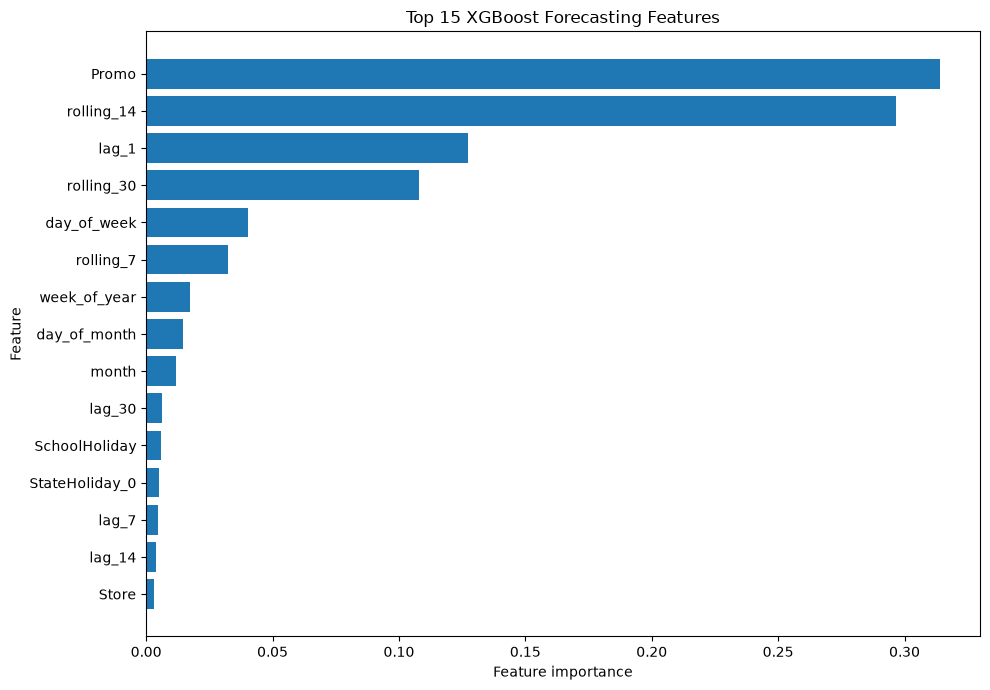

In [14]:
top_features = importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Top 15 XGBoost Forecasting Features")
plt.tight_layout()
plt.show()

## Interpretation guidance
- Importance is not causal evidence.
- Correlated features can share or distort importance.
- SHAP can be added later when a compatible trained model and exact feature matrix are available.

## Conclusion
This notebook provides a safe explainability entry point without changing or retraining the committed XGBoost model. If the importance artifact is missing, the notebook reports that limitation rather than inventing results.

## Assumptions and Limitations

- Feature importance reflects the fitted XGBoost model and its training data.
- Importance scores are relative indicators of model reliance, not proof that a feature causes sales changes.
- Correlated lag and rolling features can affect the importance ranking.
- The analysis uses historical Rossmann sales data; future feature rankings may differ.
- Sales represents revenue, not physical product units.